# 05 – Exploratory Data Analysis: Weather and Bicycle Traffic in Zurich

## Objective
Explore the weather and bicycle traffic datasets for **2023–2025** before integrating the sources. This notebook describes the distribution, seasonality, coverage, and data quality of each dataset separately.

## Research question
**How are weather conditions associated with bicycle traffic volumes in Zurich?**

The combined weather–bicycle relationships cannot be tested until the datasets are integrated using a documented and consistent time key.

## Analysis plan
1. Load the cleaned weather data and the hourly bicycle data.
2. Inspect the weather dataset and summarize weather patterns.
3. Audit the bicycle dataset, including counting stations, direction coverage, and daylight-saving transitions.
4. Explore bicycle traffic by hour, weekday, month, and counting station.
5. Record findings and the requirements for the subsequent integration step.

**Units and interpretation:** Bicycle counts are recorded passages at counting stations, not unique cyclists. Changes in the number or coverage of stations can influence summed traffic totals.

## 0. Setup and data sources

The notebook expects these files in the shared repository:

- Weather: `data/processed/weather_zurich_hourly_2023_2025_cleaned.csv` (created by member S).
- Bicycle traffic: `velo_hourly_2023_2025.csv` (created by member A), stored in `data/processed/`, `data/raw/`, or directly under `data/`.

The bicycle schema is explicitly mapped to the columns actually present in member A's file. If the bicycle file has not yet been copied into the repository, add it to one of the supported directories before running the notebook.

**Time conventions:** Weather timestamps are UTC. The bicycle column `stunde` contains timezone-naive hourly timestamps that exhibit Zurich daylight-saving transitions. For this **separate** EDA, bicycle hours are analyzed as recorded local clock hours. Do not join `stunde` directly to UTC weather timestamps or label it as UTC without verifying member A's original processing code.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Find the shared project root from the notebook working directory
current = Path.cwd().resolve()
project_root = next(
    (
        path for path in (current, *current.parents)
        if (path / "requirements.txt").is_file()
        and (path / "notebooks").is_dir()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Project root not found. Open the shared repository in VS Code "
        "and run the notebook from the repository or one of its subfolders."
    )

# Save figures separately from raw and processed data
figure_dir = project_root / "reports" / "figures" / "05_eda"
figure_dir.mkdir(parents=True, exist_ok=True)

weather_file = (
    project_root / "data" / "processed"
    / "weather_zurich_hourly_2023_2025_cleaned.csv"
)

# Search exact, known locations rather than guessing a column mapping
velo_candidates = [
    project_root / "data" / "processed" / "velo_hourly_2023_2025.csv",
    project_root / "data" / "raw" / "velo_hourly_2023_2025.csv",
    project_root / "data" / "velo_hourly_2023_2025.csv",
]
velo_file = next((path for path in velo_candidates if path.is_file()), None)

# Also support a custom subfolder under data/ if the exact filename is unique
if velo_file is None:
    nested_matches = sorted((project_root / "data").rglob("velo_hourly_2023_2025.csv"))
    if len(nested_matches) == 1:
        velo_file = nested_matches[0]
    elif len(nested_matches) > 1:
        raise ValueError(
            "Multiple bicycle CSV files found. Choose one location and remove "
            "the ambiguous extra copies: " + ", ".join(map(str, nested_matches))
        )

if not weather_file.is_file():
    raise FileNotFoundError(f"Weather file not found: {weather_file}")
if velo_file is None:
    raise FileNotFoundError(
        "Bicycle CSV not found. Copy velo_hourly_2023_2025.csv to "
        "data/processed/ (recommended), data/raw/, or data/."
    )

print("Project root:", project_root)
print("Weather file:", weather_file.relative_to(project_root))
print("Bicycle file:", velo_file.relative_to(project_root))
print("Figure directory:", figure_dir.relative_to(project_root))

Project root: C:\Sven\Studium\Fächer\2. Semester Hauptstudium\Data Analytics\Projekt\velo-wetter-zuerich-HS26\velo-wetter-zuerich-HS26
Weather file: data\processed\weather_zurich_hourly_2023_2025_cleaned.csv
Bicycle file: data\processed\velo_hourly_2023_2025.csv
Figure directory: reports\figures\05_eda


### 0.1 Load the datasets using the verified column names

**Weather fields:** `time`, `temperature_2m`, `precipitation`, `relative_humidity_2m`, `wind_speed_10m`, `cloud_cover`, `is_rainy`, `temperature_category`.

**Bicycle fields:** `FK_STANDORT`, `stunde`, `velo_in`, `velo_out`, `anzahl_intervalle`, `messungen_in`, `messungen_out`, `velo_total`.

For bicycles, `FK_STANDORT` is the counting-station ID, `stunde` is the recorded hourly timestamp, and `velo_total` is the provided total number of counted passages. A missing `velo_out` value is **not** automatically considered zero in the source data; some stations only record one direction.

In [2]:
# Read weather and bicycle data without modifying the original files
weather = pd.read_csv(weather_file)
weather_source_shape = weather.shape
velo = pd.read_csv(velo_file, dtype={"FK_STANDORT": "string"})

required_weather = [
    "time", "temperature_2m", "precipitation", "relative_humidity_2m",
    "wind_speed_10m", "cloud_cover", "is_rainy", "temperature_category",
]
required_velo = [
    "FK_STANDORT", "stunde", "velo_in", "velo_out",
    "anzahl_intervalle", "messungen_in", "messungen_out", "velo_total",
]

for label, frame, columns in [
    ("Weather", weather, required_weather),
    ("Bicycle", velo, required_velo),
]:
    missing = sorted(set(columns) - set(frame.columns))
    if missing:
        raise ValueError(f"{label} dataset is missing columns: {missing}")

# Weather timestamps were requested in UTC from Open-Meteo
weather["time"] = pd.to_datetime(weather["time"], utc=True, errors="coerce")
weather["time_zurich"] = weather["time"].dt.tz_convert("Europe/Zurich")

# Bicycle timestamps are recorded as naive local clock hours in the supplied file
velo["stunde"] = pd.to_datetime(velo["stunde"], errors="coerce")

for column in [
    "temperature_2m", "precipitation", "relative_humidity_2m",
    "wind_speed_10m", "cloud_cover",
]:
    weather[column] = pd.to_numeric(weather[column], errors="coerce")

for column in [
    "velo_in", "velo_out", "velo_total",
    "anzahl_intervalle", "messungen_in", "messungen_out",
]:
    velo[column] = pd.to_numeric(velo[column], errors="coerce")

print("Weather file dimensions:", weather_source_shape)
print("Weather working dimensions (including local time):", weather.shape)
print("Bicycle file dimensions:", velo.shape)
print("Number of bicycle stations:", velo["FK_STANDORT"].nunique())
print("\nWeather preview:")
display(weather[required_weather].head())
print("\nBicycle preview:")
display(velo[required_velo].head())

Weather file dimensions: (26304, 8)
Weather working dimensions (including local time): (26304, 9)
Bicycle file dimensions: (587954, 8)
Number of bicycle stations: 33

Weather preview:


,time,temperature_2m,precipitation,relative_humidity_2m,wind_speed_10m,cloud_cover,is_rainy,temperature_category
0,2023-01-01 00:00:00+00:00,8.1,0.0,84,5.1,74,False,0-10°C
1,2023-01-01 01:00:00+00:00,8.2,0.0,83,4.6,48,False,0-10°C
2,2023-01-01 02:00:00+00:00,8.4,0.0,85,3.6,48,False,0-10°C
3,2023-01-01 03:00:00+00:00,8.0,0.0,86,2.9,61,False,0-10°C
4,2023-01-01 04:00:00+00:00,8.0,0.0,86,3.2,41,False,0-10°C



Bicycle preview:


,FK_STANDORT,stunde,velo_in,velo_out,anzahl_intervalle,messungen_in,messungen_out,velo_total
0,60,2023-01-01 00:00:00,0.0,1.0,4,4,4,1.0
1,60,2023-01-01 01:00:00,0.0,2.0,4,4,4,2.0
2,60,2023-01-01 02:00:00,0.0,3.0,4,4,4,3.0
3,60,2023-01-01 03:00:00,2.0,2.0,4,4,4,4.0
4,60,2023-01-01 04:00:00,0.0,0.0,4,4,4,0.0


## 1. Weather data exploration

### 1.1 Data quality and descriptive statistics

The 2023–2025 UTC interval contains 26,304 hourly timestamps, including the leap year 2024. Check timestamp coverage, duplicate timestamps, and missing meteorological values before generating descriptive plots.

In [3]:
# Validate weather coverage and data quality
expected_weather_hours = pd.date_range(
    "2023-01-01 00:00:00",
    "2025-12-31 23:00:00",
    freq="h", tz="UTC",
)
missing_weather_hours = expected_weather_hours.difference(weather["time"].dropna())
weather_measures = [
    "temperature_2m", "precipitation", "relative_humidity_2m",
    "wind_speed_10m", "cloud_cover",
]

weather_quality = pd.DataFrame({
    "Check": [
        "Rows", "Expected hourly timestamps", "Unique timestamps",
        "Invalid timestamps", "Duplicate timestamps", "Missing hourly timestamps",
        "Missing numeric weather values",
    ],
    "Value": [
        len(weather), len(expected_weather_hours), weather["time"].nunique(),
        int(weather["time"].isna().sum()),
        int(weather["time"].duplicated().sum()),
        len(missing_weather_hours),
        int(weather[weather_measures].isna().sum().sum()),
    ],
})
print("Weather data quality:")
display(weather_quality)
print("\nWeather descriptive statistics:")
display(weather[weather_measures].describe().round(2))

Weather data quality:


,Check,Value
0,Rows,26304
1,Expected hourly timestamps,26304
2,Unique timestamps,26304
3,Invalid timestamps,0
4,Duplicate timestamps,0
5,Missing hourly timestamps,0
6,Missing numeric weather values,0



Weather descriptive statistics:


,temperature_2m,precipitation,relative_humidity_2m,wind_speed_10m,cloud_cover
count,26304.00,26304.00,26304.00,26304.00,26304.00
mean,11.73,0.14,78.54,6.60,64.85
std,7.90,0.38,15.58,4.57,34.91
min,-7.70,0.00,23.00,0.00,0.00
25%,5.70,0.00,70.00,3.30,35.00
50%,11.20,0.00,83.00,5.60,77.00
75%,17.40,0.10,91.00,8.80,98.00
max,35.90,6.60,100.00,34.30,100.00


### 1.2 Monthly and annual weather summaries

Monthly temperature is the **mean of hourly temperatures**; monthly precipitation is the **sum of hourly precipitation in millimetres**. Calendar months are computed in UTC for consistency with the source time range. Local Zurich clock time is used separately in the diurnal profile.

In [4]:
# Aggregate hourly weather observations to months and years
monthly_weather = (
    weather.set_index("time")
    .resample("MS")
    .agg(
        mean_temperature_c=("temperature_2m", "mean"),
        precipitation_mm=("precipitation", "sum"),
        mean_humidity_pct=("relative_humidity_2m", "mean"),
        mean_wind_kmh=("wind_speed_10m", "mean"),
        observed_hours=("temperature_2m", "count"),
    )
    .reset_index()
)
monthly_weather["year"] = monthly_weather["time"].dt.year
monthly_weather["month"] = monthly_weather["time"].dt.month

annual_weather = (
    weather.groupby(weather["time"].dt.year)
    .agg(
        mean_temperature_c=("temperature_2m", "mean"),
        total_precipitation_mm=("precipitation", "sum"),
        mean_humidity_pct=("relative_humidity_2m", "mean"),
        mean_wind_kmh=("wind_speed_10m", "mean"),
        observed_hours=("temperature_2m", "count"),
    )
)
annual_weather.index.name = "year"
print("Annual weather summary:")
display(annual_weather.round(2))
print("\nMonthly weather summary (first 12 months):")
display(monthly_weather.head(12).round(2))

Annual weather summary:


,mean_temperature_c,total_precipitation_mm,mean_humidity_pct,mean_wind_kmh,observed_hours
year,,,,,
2023,12.15,1235.8,76.59,7.34,8760
2024,11.78,1224.5,80.72,6.47,8784
2025,11.25,1148.7,78.32,6.00,8760



Monthly weather summary (first 12 months):


C:\Users\svend\AppData\Local\Temp\ipykernel_31352\4009863756.py:31: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_weather.head(12).round(2))


,time,mean_temperature_c,precipitation_mm,mean_humidity_pct,mean_wind_kmh,observed_hours,year,month
0,2023-01-01 00:00:00+00:00,3.56,51.9,83.26,8.39,744,2023,1
1,2023-02-01 00:00:00+00:00,3.92,32.0,77.88,7.64,672,2023,2
2,2023-03-01 00:00:00+00:00,7.83,117.8,74.09,8.22,744,2023,3
3,2023-04-01 00:00:00+00:00,9.20,133.8,76.43,8.07,720,2023,4
4,2023-05-01 00:00:00+00:00,14.98,117.7,76.04,7.59,744,2023,5
5,2023-06-01 00:00:00+00:00,20.82,38.8,59.09,6.61,720,2023,6
6,2023-07-01 00:00:00+00:00,21.13,107.0,68.38,6.87,744,2023,7
7,2023-08-01 00:00:00+00:00,20.60,142.5,73.87,6.34,744,2023,8
8,2023-09-01 00:00:00+00:00,18.76,66.6,76.55,4.59,720,2023,9
9,2023-10-01 00:00:00+00:00,13.21,83.2,80.75,6.07,744,2023,10


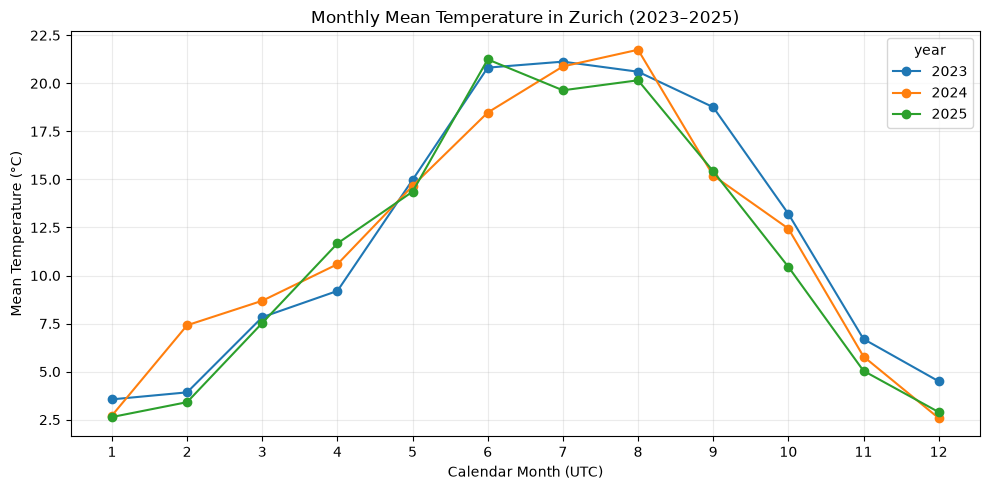

In [5]:
# Compare monthly mean temperatures between the three years
monthly_temperature = monthly_weather.pivot(
    index="month", columns="year", values="mean_temperature_c"
)
ax = monthly_temperature.plot(marker="o", figsize=(10, 5))
ax.set(
    title="Monthly Mean Temperature in Zurich (2023–2025)",
    xlabel="Calendar Month (UTC)",
    ylabel="Mean Temperature (°C)",
)
ax.set_xticks(range(1, 13))
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(figure_dir / "weather_monthly_temperature.png", dpi=150)
plt.show()

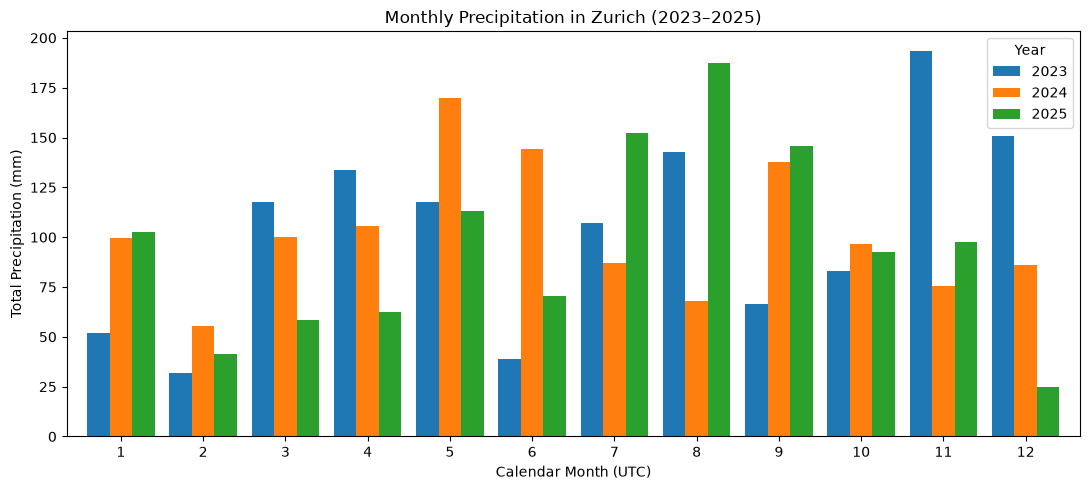

In [6]:
# Compare monthly precipitation totals between years
monthly_precipitation = monthly_weather.pivot(
    index="month", columns="year", values="precipitation_mm"
)
ax = monthly_precipitation.plot(kind="bar", figsize=(11, 5), width=0.82)
ax.set(
    title="Monthly Precipitation in Zurich (2023–2025)",
    xlabel="Calendar Month (UTC)",
    ylabel="Total Precipitation (mm)",
)
ax.legend(title="Year")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(figure_dir / "weather_monthly_precipitation.png", dpi=150)
plt.show()

### 1.3 Weather distributions and local-time patterns

A wet hour is defined as an hour with recorded precipitation **greater than 0 mm**. This is a measurement-based flag and does not imply that precipitation was intense or persistent. Hour-of-day analyses use the `Europe/Zurich` local hour derived from the UTC weather timestamps.

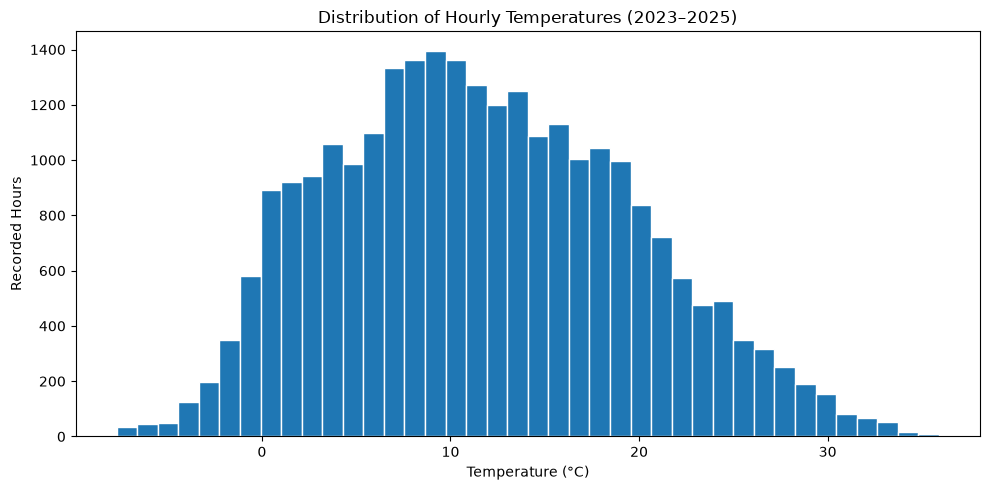

Recorded wet and dry hours:


,Weather condition,Hours,Percentage
0,Dry hour,18904,71.87
1,Wet hour,7400,28.13


In [7]:
# Show the temperature distribution
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(weather["temperature_2m"].dropna(), bins=40, edgecolor="white")
ax.set(
    title="Distribution of Hourly Temperatures (2023–2025)",
    xlabel="Temperature (°C)",
    ylabel="Recorded Hours",
)
plt.tight_layout()
plt.savefig(figure_dir / "weather_temperature_histogram.png", dpi=150)
plt.show()

# Summarize hours with and without recorded precipitation
weather["rainy_hour"] = weather["precipitation"] > 0
rain_summary = (
    weather["rainy_hour"]
    .value_counts()
    .rename(index={True: "Wet hour", False: "Dry hour"})
    .rename_axis("Weather condition")
    .reset_index(name="Hours")
)
rain_summary["Percentage"] = 100 * rain_summary["Hours"] / len(weather)
print("Recorded wet and dry hours:")
display(rain_summary.round(2))

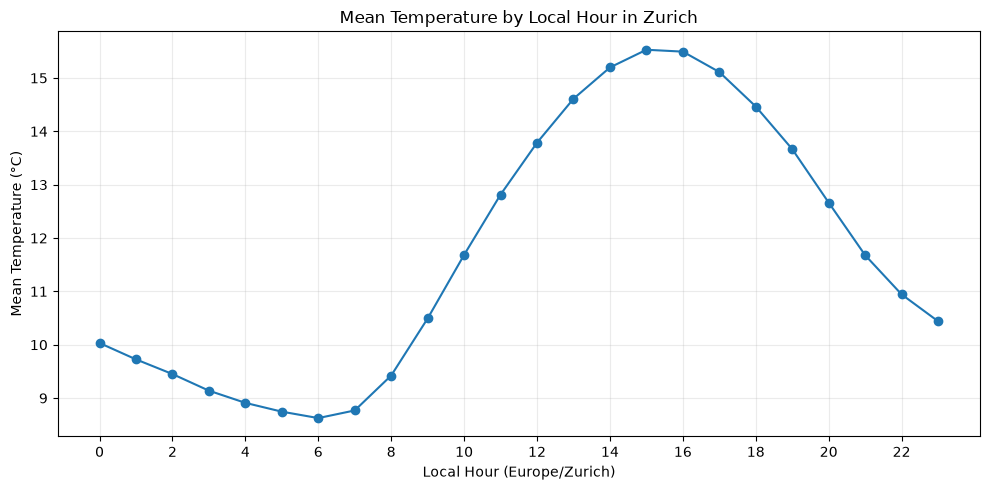

In [8]:
# Calculate the mean temperature for each local hour of the day
weather["local_hour"] = weather["time_zurich"].dt.hour
mean_temperature_by_local_hour = (
    weather.groupby("local_hour")["temperature_2m"].mean()
)
ax = mean_temperature_by_local_hour.plot(marker="o", figsize=(10, 5))
ax.set(
    title="Mean Temperature by Local Hour in Zurich",
    xlabel="Local Hour (Europe/Zurich)",
    ylabel="Mean Temperature (°C)",
)
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(figure_dir / "weather_local_hour_temperature.png", dpi=150)
plt.show()

### 1.4 Descriptive correlation analysis of weather variables

Pearson correlations describe **linear associations** among the five weather variables. This descriptive correlation matrix is **not a statistical significance test** and does not imply causation. Hypothesis tests with p-values can be completed later in the advanced analysis notebook.

Weather correlations:


,temperature_2m,precipitation,relative_humidity_2m,wind_speed_10m,cloud_cover
temperature_2m,1.00,0.02,-0.57,-0.00,-0.12
precipitation,0.02,1.00,0.21,0.20,0.29
relative_humidity_2m,-0.57,0.21,1.00,-0.20,0.27
wind_speed_10m,-0.00,0.20,-0.20,1.00,0.17
cloud_cover,-0.12,0.29,0.27,0.17,1.00


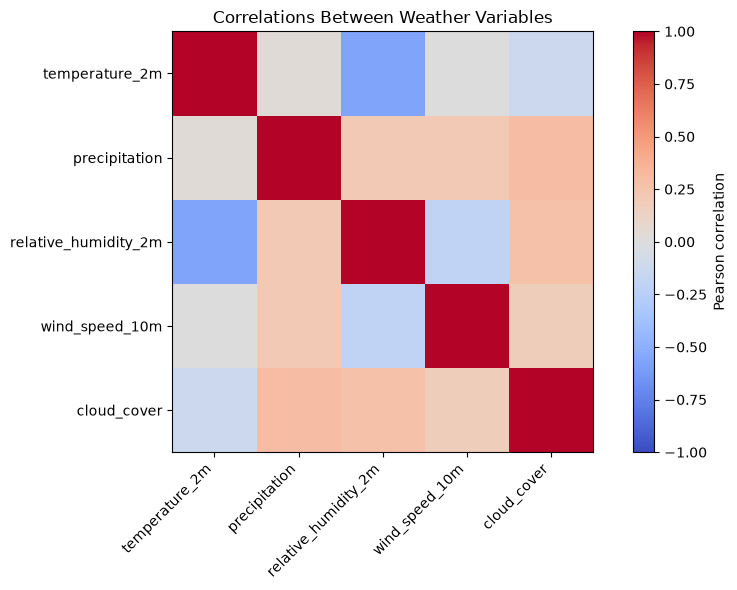

In [9]:
# Inspect Pearson correlations among measured weather variables
weather_correlations = weather[weather_measures].corr(method="pearson")
print("Weather correlations:")
display(weather_correlations.round(2))

fig, ax = plt.subplots(figsize=(9, 6))
image = ax.imshow(weather_correlations, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(weather_measures)), labels=weather_measures, rotation=45, ha="right")
ax.set_yticks(range(len(weather_measures)), labels=weather_measures)
fig.colorbar(image, ax=ax, label="Pearson correlation")
ax.set_title("Correlations Between Weather Variables")
plt.tight_layout()
plt.savefig(figure_dir / "weather_correlation_matrix.png", dpi=150)
plt.show()

### 1.5 Weather EDA Interpretation

#### Temperature Seasonality

The temperature analysis reveals a clear seasonal pattern in Zurich between 2023 and 2025.

Average temperatures are lowest during the winter months (December to February) and highest during the summer months (June to August).

The highest monthly average temperature was recorded in August 2024, reaching approximately 21.7°C. In contrast, the lowest monthly averages were observed during the winter months, at approximately 2.5–4°C.

Some differences between the three years are noticeable. For example, February 2024 was considerably warmer than February 2023 and February 2025. Furthermore, June 2025 was warmer than June 2024.

Overall, the results demonstrate strong seasonal temperature fluctuations, which should be considered when analyzing bicycle traffic patterns.

#### Temperature Distribution

The histogram illustrates the distribution of hourly temperatures from 2023 to 2025.

Most recorded temperatures fall between approximately 5°C and 20°C, with the highest frequency occurring around 8–12°C.

Extremely low temperatures below 0°C and high temperatures above 30°C occur considerably less frequently.

This distribution is important for the subsequent analysis because bicycle traffic observations under extreme weather conditions may be less frequent than observations under moderate temperatures.

#### Precipitation Analysis

The precipitation analysis shows substantial monthly and yearly variations between 2023 and 2025.

In 2023, November recorded the highest monthly precipitation, with approximately 194 mm.

In 2024, May had the highest precipitation total, reaching approximately 170 mm.

In 2025, August recorded the highest precipitation, with approximately 187 mm, while December had a particularly low total of approximately 25 mm.

These results indicate that precipitation does not follow an identical seasonal pattern across all three years.

The variation in precipitation provides an important basis for investigating whether bicycle traffic differs between wet and dry conditions.

#### Daily Temperature Pattern

The hourly temperature analysis reveals a clear daily temperature cycle.

The lowest average temperatures occur during the early morning hours, particularly around 06:00, with approximately 8.6°C.

Temperatures increase throughout the morning and reach their highest average values between 15:00 and 16:00, at approximately 15.5°C.

After this peak, temperatures gradually decrease throughout the evening and nighttime hours.

The difference between the lowest and highest hourly average temperatures is approximately 7°C.

These findings demonstrate that temperature varies considerably throughout the day. Therefore, the time of day should be considered when analyzing relationships between weather conditions and bicycle traffic.

#### Correlation Analysis

The Pearson correlation matrix illustrates the linear relationships between the five weather variables.

The strongest negative relationship is observed between temperature and relative humidity. This indicates that higher temperatures tend to be associated with lower relative humidity.

Positive correlations are visible between precipitation and cloud cover, as well as between relative humidity and cloud cover.

These relationships suggest that cloudier conditions tend to coincide with increased humidity and precipitation.

The remaining relationships are generally weak or moderate.

It is important to note that correlation does not imply causation. Furthermore, the correlation matrix provides descriptive coefficients but does not establish statistical significance without additional hypothesis tests and p-values.

#### Data Limitations

The weather data originates from the Open-Meteo Historical Weather API using the ERA5 reanalysis model.

The dataset contains 26,304 hourly observations covering January 2023 through December 2025.

Although the dataset provides continuous weather information without missing values, the measurements represent modeled weather conditions for a geographical grid location rather than direct observations at every bicycle counting station.

Additionally, the exploratory analysis examines the weather variables independently of bicycle traffic.

Therefore, no conclusions about the influence of weather conditions on bicycle traffic can be drawn at this stage.

These relationships will be investigated after integrating the weather and bicycle traffic datasets.

## 2. Bicycle traffic exploration

### 2.1 Recorded schema and quality checks

The supplied hourly bicycle CSV contains these eight columns:

| Column | Meaning for this analysis |
|---|---|
| `FK_STANDORT` | Counting-station identifier |
| `stunde` | Hourly timestamp recorded by the bicycle processing pipeline |
| `velo_in` | Bicycle passages counted in the inbound direction |
| `velo_out` | Bicycle passages counted in the outbound direction, when available |
| `anzahl_intervalle` | Number of underlying measurement intervals aggregated into the row |
| `messungen_in` | Number of available inbound measurements |
| `messungen_out` | Number of available outbound measurements |
| `velo_total` | Total passages provided by member A's preparation pipeline |

**Important:** 68,774 rows in the uploaded CSV have an empty `velo_out`. They are concentrated in stations that do not provide outbound counts, so the missing cells should not be blindly imputed or interpreted as zero measurements. The analysis of total passages uses the existing `velo_total` column.

In [10]:
# Inspect the exact bicycle schema and the missing-value profile
print("Bicycle dataset dimensions:", velo.shape)
print("Number of counting stations:", velo["FK_STANDORT"].nunique())
print("Bicycle data types:")
display(velo.dtypes.rename("dtype").to_frame())
print("\nMissing values by column:")
display(velo[required_velo].isna().sum().rename("missing_values").to_frame())
print("\nBicycle count summary:")
display(velo[["velo_in", "velo_out", "velo_total"]].describe().round(2))

Bicycle dataset dimensions: (587954, 8)
Number of counting stations: 33
Bicycle data types:


,dtype
FK_STANDORT,string
stunde,datetime64[us]
velo_in,float64
velo_out,float64
anzahl_intervalle,int64
messungen_in,int64
messungen_out,int64
velo_total,float64



Missing values by column:


,missing_values
FK_STANDORT,0
stunde,0
velo_in,0
velo_out,68774
anzahl_intervalle,0
messungen_in,0
messungen_out,0
velo_total,0



Bicycle count summary:


,velo_in,velo_out,velo_total
count,587954.00,519180.00,587954.00
mean,40.73,24.93,62.74
std,57.36,33.75,77.86
min,0.00,0.00,0.00
25%,4.00,2.00,9.00
50%,20.00,12.00,37.00
75%,53.00,36.00,85.00
max,1721.00,1526.00,1875.00


In [11]:
# Audit station-hour uniqueness, negative totals, and the supplied total calculation
n_duplicate_site_hours = int(velo.duplicated(["FK_STANDORT", "stunde"]).sum())
n_duplicate_rows = int(velo.duplicated().sum())
n_invalid_timestamps = int(velo["stunde"].isna().sum())
n_negative_totals = int((velo["velo_total"] < 0).sum())

# The file's supplied total uses the available directional counts
calculated_available_directions = velo["velo_in"].fillna(0) + velo["velo_out"].fillna(0)
n_total_mismatches = int((~np.isclose(
    velo["velo_total"].fillna(-1),
    calculated_available_directions,
    rtol=0, atol=1e-9,
)).sum())

bicycle_quality = pd.DataFrame({
    "Check": [
        "Rows", "Counting stations", "Unique recorded clock hours",
        "Invalid timestamps", "Duplicate full rows",
        "Duplicate station-hour keys", "Missing total counts",
        "Negative total counts", "Missing outbound counts",
        "Total vs. sum of available directions: mismatches",
    ],
    "Value": [
        len(velo), velo["FK_STANDORT"].nunique(),
        velo["stunde"].nunique(), n_invalid_timestamps,
        n_duplicate_rows, n_duplicate_site_hours,
        int(velo["velo_total"].isna().sum()), n_negative_totals,
        int(velo["velo_out"].isna().sum()), n_total_mismatches,
    ],
})
print("Bicycle data quality:")
display(bicycle_quality)

Bicycle data quality:


,Check,Value
0,Rows,587954
1,Counting stations,33
2,Unique recorded clock hours,26301
3,Invalid timestamps,0
4,Duplicate full rows,0
5,Duplicate station-hour keys,0
6,Missing total counts,0
7,Negative total counts,0
8,Missing outbound counts,68774
9,Total vs. sum of available directions: mismatches,0


### 2.2 Daylight-saving time and measurement interval coverage

The `stunde` timestamps are **timezone-naive**. The source file has the hallmarks of Zurich local time:

- On the spring-forward date each year, the local `02:00` clock hour does not occur.
- On the autumn rollback date, the two occurrences of `02:00` may be combined into one station-hour row containing **eight 15-minute intervals**, rather than the usual four.

These are **not ordinary missing rows or duplicate station-hour errors**. They require an explicit strategy before integrating with the UTC weather series. This notebook does not silently localize or convert the ambiguous bicycle timestamps to UTC.

For apples-to-apples descriptive hourly comparisons, plots below use only rows with **four aggregated intervals**. This excludes the unusually short or long rows from rate comparisons, without modifying or deleting them from the source dataset.

In [12]:
# Compare observed clock hours with the complete naive hourly calendar
expected_clock_hours = pd.date_range(
    "2023-01-01 00:00:00", "2025-12-31 23:00:00", freq="h"
)
missing_clock_hours = expected_clock_hours.difference(velo["stunde"].dropna())
print("Clock hours missing from the source timeline:")
display(pd.DataFrame({"missing_clock_hour": missing_clock_hours}))

print("\nNumber of measurement intervals per station-hour:")
interval_summary = (
    velo["anzahl_intervalle"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("number_of_intervals")
    .reset_index(name="station_hour_rows")
)
display(interval_summary)

print("\nLocal dates with eight intervals per station-hour:")
display(
    velo.loc[velo["anzahl_intervalle"].eq(8)]
    .groupby("stunde")
    .agg(stations=("FK_STANDORT", "nunique"), rows=("velo_total", "size"))
    .reset_index()
)

Clock hours missing from the source timeline:


,missing_clock_hour
0,2023-03-26 02:00:00
1,2024-03-31 02:00:00
2,2025-03-30 02:00:00



Number of measurement intervals per station-hour:


,number_of_intervals,station_hour_rows
0,1,16
1,2,14
2,3,9
3,4,587849
4,8,66



Local dates with eight intervals per station-hour:


,stunde,stations,rows
0,2023-10-29 02:00:00,23,23
1,2024-10-27 02:00:00,23,23
2,2025-10-26 02:00:00,20,20


### 2.3 Station and direction availability

The number of active counting stations changes over time. Therefore, a rise or fall in **summed counts across all stations** may reflect changes in network coverage rather than changes in actual cycling behavior.

We inspect recording coverage and select a relatively stable set of stations for comparisons between calendar years. This panel is defined explicitly and reproducibly below; it is an analytical choice, not a claim that other stations are incorrect.

In [13]:
# Describe all counting stations and their source-data coverage
first_to_last = (
    velo.groupby("FK_STANDORT")
    .agg(
        first_record=("stunde", "min"),
        last_record=("stunde", "max"),
        observed_hours=("stunde", "nunique"),
        total_passages=("velo_total", "sum"),
        missing_outbound=("velo_out", lambda values: int(values.isna().sum())),
    )
)
months_per_station = (
    velo.assign(recorded_month=velo["stunde"].dt.to_period("M"))
    .groupby("FK_STANDORT")["recorded_month"]
    .nunique()
    .rename("months_present")
)
station_summary = first_to_last.join(months_per_station)
station_summary["coverage_pct"] = (
    100 * station_summary["observed_hours"] / velo["stunde"].nunique()
)
station_summary = station_summary.sort_values("observed_hours", ascending=False)

print("Counting-station coverage (top 15 by observed hours):")
display(station_summary.head(15).round(2))
print("\nCounting stations with missing outbound measurements:")
display(
    station_summary.loc[station_summary["missing_outbound"] > 0,
                        ["observed_hours", "missing_outbound", "months_present"]]
)

Counting-station coverage (top 15 by observed hours):


C:\Users\svend\AppData\Local\Temp\ipykernel_31352\1672167843.py:25: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(station_summary.head(15).round(2))


,first_record,last_record,observed_hours,total_passages,missing_outbound,months_present,coverage_pct
FK_STANDORT,,,,,,,
1037,2023-01-01,2025-12-31 23:00:00,26277,2882864.0,0,36,99.91
2997,2023-01-01,2025-12-31 23:00:00,26277,1185914.0,0,36,99.91
2989,2023-01-01,2025-12-31 23:00:00,26277,3935142.0,0,36,99.91
4241,2023-01-01,2025-12-31 23:00:00,26277,974142.0,0,36,99.91
5002,2023-01-01,2025-12-31 23:00:00,26277,1917084.0,0,36,99.91
732,2023-01-01,2025-12-31 23:00:00,26277,1319986.0,0,36,99.91
3012,2023-01-01,2025-12-31 23:00:00,26275,1572880.0,0,36,99.90
4249,2023-01-01,2025-12-31 23:00:00,26275,3402116.0,0,36,99.90
4242,2023-01-01,2025-12-31 23:00:00,26229,1157792.0,0,36,99.73



Counting stations with missing outbound measurements:


,observed_hours,missing_outbound,months_present
FK_STANDORT,,,
4258,25819,25819,36
4267,21309,21309,30
2982,11855,11855,17
4272,5760,5760,8
3008,3719,3719,7
2977,312,312,1


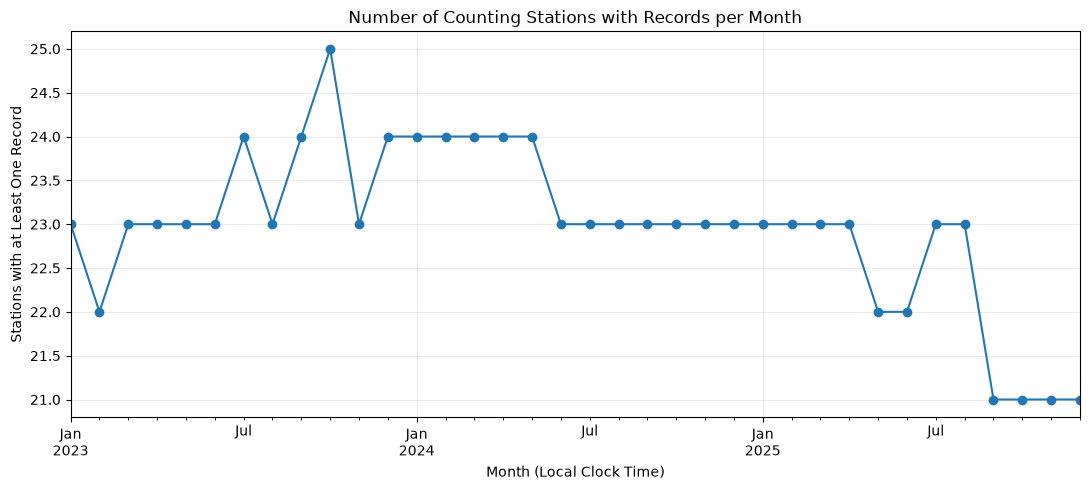

Annual bicycle coverage summary:


,station_hour_rows,stations_with_records,recorded_passages
year,,,
2023,196131,31,11816949.0
2024,204193,24,12393878.0
2025,187630,25,12680001.0


Annual passage totals are not directly comparable when station coverage changes.


In [14]:
# Plot the number of recording stations in each month
monthly_station_coverage = (
    velo.assign(month=velo["stunde"].dt.to_period("M"))
    .groupby("month")["FK_STANDORT"].nunique()
)
monthly_station_coverage.index = monthly_station_coverage.index.to_timestamp()

ax = monthly_station_coverage.plot(marker="o", figsize=(11, 5))
ax.set(
    title="Number of Counting Stations with Records per Month",
    xlabel="Month (Local Clock Time)",
    ylabel="Stations with at Least One Record",
)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(figure_dir / "velo_active_stations_by_month.png", dpi=150)
plt.show()

print("Annual bicycle coverage summary:")
annual_bicycle_coverage = (
    velo.assign(year=velo["stunde"].dt.year)
    .groupby("year")
    .agg(
        station_hour_rows=("velo_total", "size"),
        stations_with_records=("FK_STANDORT", "nunique"),
        recorded_passages=("velo_total", "sum"),
    )
)
display(annual_bicycle_coverage.round(2))
print("Annual passage totals are not directly comparable when station coverage changes.")

### 2.4 A stable station panel for time comparisons

The stable panel includes stations that:

1. Have records in **all 36 months** between January 2023 and December 2025.
2. Cover at least **95% of the unique recorded clock hours** in the full bicycle source.

For descriptive hourly and monthly comparisons, only rows with **exactly four 15-minute intervals** are retained, to avoid comparing a doubled autumn clock hour or an incomplete hour with a normal hour. The `velo_total` data remain unchanged; this is a **filtered analysis view**, not a new cleaned file.

The unit of analysis is **recorded passages per station-hour**, not unique citywide cyclists. The panel threshold is shown so its consequences can be justified in the project report.

In [15]:
# Define a reproducible, relatively stable station panel
MIN_COVERAGE_PCT = 95.0
REQUIRED_MONTHS = 36
stable_station_ids = station_summary.index[
    (station_summary["months_present"] == REQUIRED_MONTHS)
    & (station_summary["coverage_pct"] >= MIN_COVERAGE_PCT)
]

if len(stable_station_ids) == 0:
    raise ValueError("No stations meet the panel coverage criteria. Review the thresholds.")

# Keep valid, nonnegative, standard four-interval station-hours for comparisons
velo_standard = velo.loc[
    velo["stunde"].notna()
    & velo["velo_total"].notna()
    & velo["velo_total"].ge(0)
    & velo["anzahl_intervalle"].eq(4)
].copy()
velo_panel = velo_standard.loc[
    velo_standard["FK_STANDORT"].isin(stable_station_ids)
].copy()

velo_panel["year"] = velo_panel["stunde"].dt.year
velo_panel["month"] = velo_panel["stunde"].dt.month
velo_panel["hour"] = velo_panel["stunde"].dt.hour
velo_panel["weekday"] = velo_panel["stunde"].dt.dayofweek
velo_panel["is_weekend"] = velo_panel["weekday"] >= 5

print("Stable panel: counting stations:", len(stable_station_ids))
print("Stable station IDs:", ", ".join(stable_station_ids.astype(str)))
print("All valid four-interval station-hours:", len(velo_standard))
print("Selected station-hours in the stable panel:", len(velo_panel))
print("Rows excluded from standard-hour comparisons:", len(velo) - len(velo_standard))
print("\nStable panel source coverage:")
display(station_summary.loc[stable_station_ids].round(2))

Stable panel: counting stations: 12
Stable station IDs: 1037, 2997, 2989, 4241, 5002, 732, 3012, 4249, 4242, 4255, 4258, 3003
All valid four-interval station-hours: 587849
Selected station-hours in the stable panel: 314007
Rows excluded from standard-hour comparisons: 105

Stable panel source coverage:


C:\Users\svend\AppData\Local\Temp\ipykernel_31352\226713384.py:26: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  velo_panel["weekday"] = velo_panel["stunde"].dt.dayofweek
C:\Users\svend\AppData\Local\Temp\ipykernel_31352\226713384.py:35: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(station_summary.loc[stable_station_ids].round(2))


,first_record,last_record,observed_hours,total_passages,missing_outbound,months_present,coverage_pct
FK_STANDORT,,,,,,,
1037,2023-01-01,2025-12-31 23:00:00,26277,2882864.0,0,36,99.91
2997,2023-01-01,2025-12-31 23:00:00,26277,1185914.0,0,36,99.91
2989,2023-01-01,2025-12-31 23:00:00,26277,3935142.0,0,36,99.91
4241,2023-01-01,2025-12-31 23:00:00,26277,974142.0,0,36,99.91
5002,2023-01-01,2025-12-31 23:00:00,26277,1917084.0,0,36,99.91
732,2023-01-01,2025-12-31 23:00:00,26277,1319986.0,0,36,99.91
3012,2023-01-01,2025-12-31 23:00:00,26275,1572880.0,0,36,99.90
4249,2023-01-01,2025-12-31 23:00:00,26275,3402116.0,0,36,99.90
4242,2023-01-01,2025-12-31 23:00:00,26229,1157792.0,0,36,99.73


### 2.5 Bicycle passages by hour of the day

The figure shows the **average number of recorded passages per station-hour** in the stable panel, not the sum across all active stations. This reduces sensitivity to a varying number of source records. It does not eliminate selection effects, holidays, or within-year variation.

Bicycle passages by local hour:


,mean_passages,median_passages,observations
hour,,,
0,19.46,9.0,13081
1,10.75,4.0,13083
2,6.78,2.0,13016
3,4.61,1.0,13087
4,4.04,2.0,13087
5,9.84,7.0,13087
6,33.68,27.0,13087
7,96.39,74.0,13087
8,136.28,104.0,13087


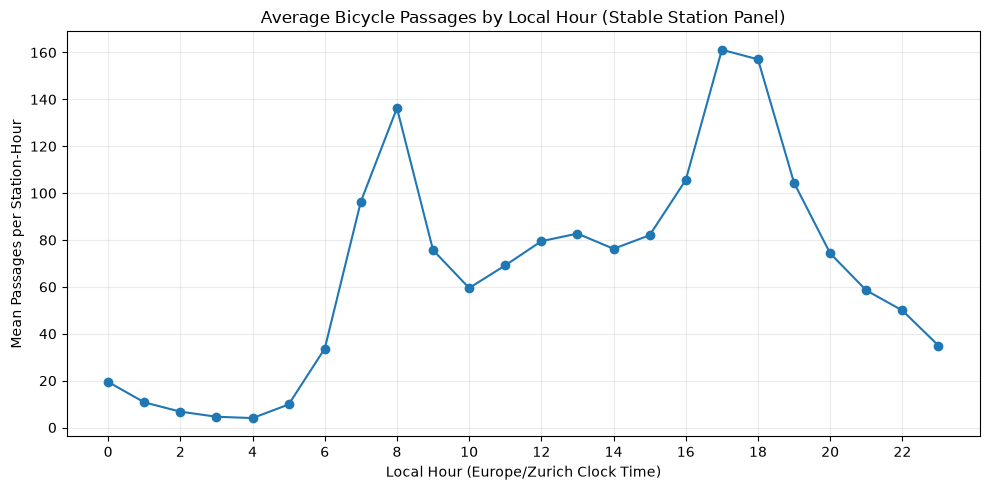

In [16]:
# Calculate average passages per standard station-hour for each local hour
traffic_by_hour = (
    velo_panel.groupby("hour")["velo_total"]
    .agg(mean_passages="mean", median_passages="median", observations="size")
)
print("Bicycle passages by local hour:")
display(traffic_by_hour.round(2))

ax = traffic_by_hour["mean_passages"].plot(marker="o", figsize=(10, 5))
ax.set(
    title="Average Bicycle Passages by Local Hour (Stable Station Panel)",
    xlabel="Local Hour (Europe/Zurich Clock Time)",
    ylabel="Mean Passages per Station-Hour",
)
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(figure_dir / "velo_mean_passages_by_hour.png", dpi=150)
plt.show()

### 2.6 Bicycle passages by weekday and weekend

Weekday analysis uses the average passage count **per observed station-hour**, not total passages summed across unequal numbers of weekdays. Monday is coded as 0 and Sunday as 6 in the data preparation code.

Bicycle passages by weekday:


,mean_passages,median_passages,observations
Monday,67.09,40.0,44779
Tuesday,79.00,47.0,45048
Wednesday,77.40,48.0,45019
Thursday,76.41,47.0,44736
Friday,70.37,46.0,44736
Saturday,53.46,32.0,44736
Sunday,40.89,23.0,44953


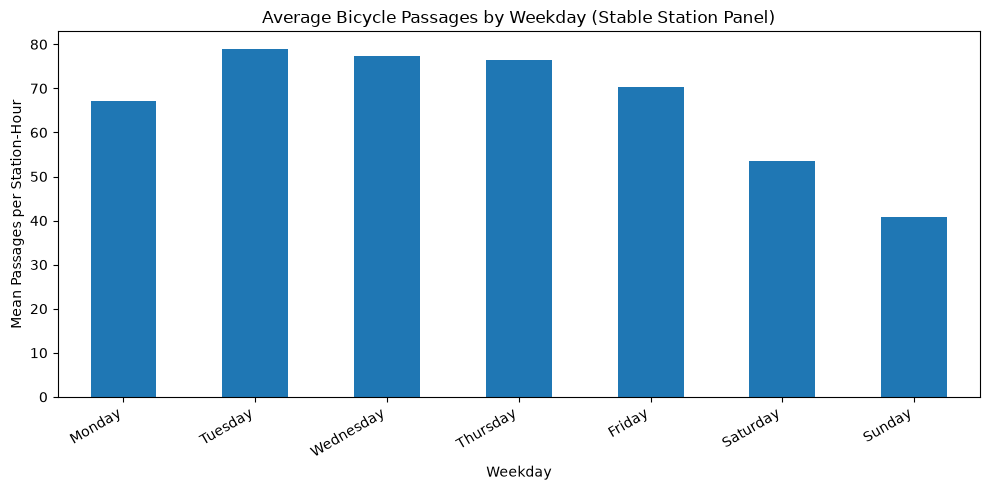

In [17]:
# Compare average passages per station-hour by weekday
weekday_names = [
    "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"
]
traffic_by_weekday = (
    velo_panel.groupby("weekday")["velo_total"]
    .agg(mean_passages="mean", median_passages="median", observations="size")
    .reindex(range(7))
)
traffic_by_weekday.index = weekday_names
print("Bicycle passages by weekday:")
display(traffic_by_weekday.round(2))

ax = traffic_by_weekday["mean_passages"].plot(kind="bar", figsize=(10, 5))
ax.set(
    title="Average Bicycle Passages by Weekday (Stable Station Panel)",
    xlabel="Weekday",
    ylabel="Mean Passages per Station-Hour",
)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(figure_dir / "velo_mean_passages_by_weekday.png", dpi=150)
plt.show()

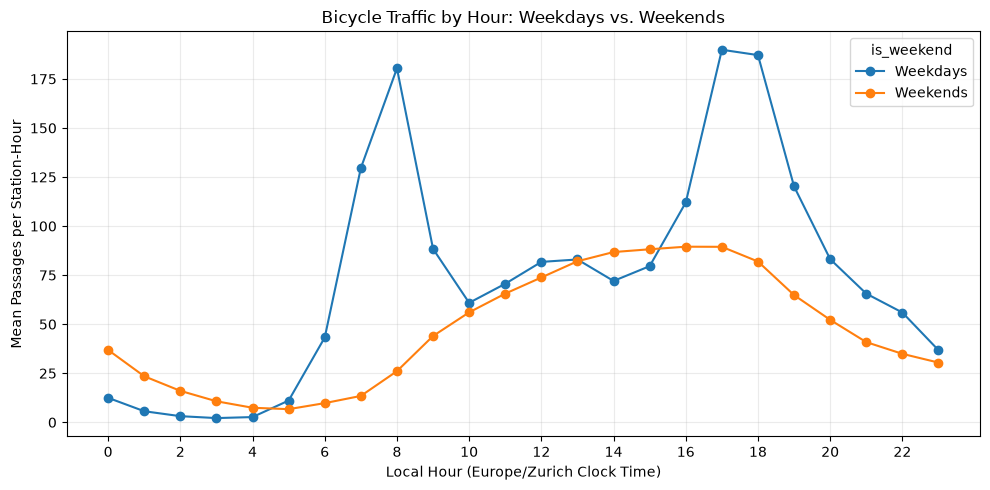

In [18]:
# Compare daily traffic shapes on weekdays and weekends
hourly_weekend_comparison = (
    velo_panel.groupby(["hour", "is_weekend"])["velo_total"]
    .mean()
    .unstack("is_weekend")
    .rename(columns={False: "Weekdays", True: "Weekends"})
)
ax = hourly_weekend_comparison.plot(marker="o", figsize=(10, 5))
ax.set(
    title="Bicycle Traffic by Hour: Weekdays vs. Weekends",
    xlabel="Local Hour (Europe/Zurich Clock Time)",
    ylabel="Mean Passages per Station-Hour",
)
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(figure_dir / "velo_weekday_weekend_hourly.png", dpi=150)
plt.show()

### 2.7 Monthly bicycle traffic, 2023–2025

This figure compares **mean passages per recorded station-hour** for a fixed set of stations across years. Differences can reflect weather, seasonality, road works, route changes, holidays, counter faults, or other factors. The weather explanation is **not** evaluated until the actual datasets are joined.

Monthly mean passages per observed station-hour:


year,2023,2024,2025
month,,,
1,42.21,37.21,44.72
2,47.46,52.75,47.66
3,57.88,57.92,65.12
4,54.16,66.31,72.80
5,73.21,70.55,77.87
6,106.12,84.65,93.16
7,81.31,87.90,76.94
8,80.20,93.80,84.28
9,91.29,74.67,73.82


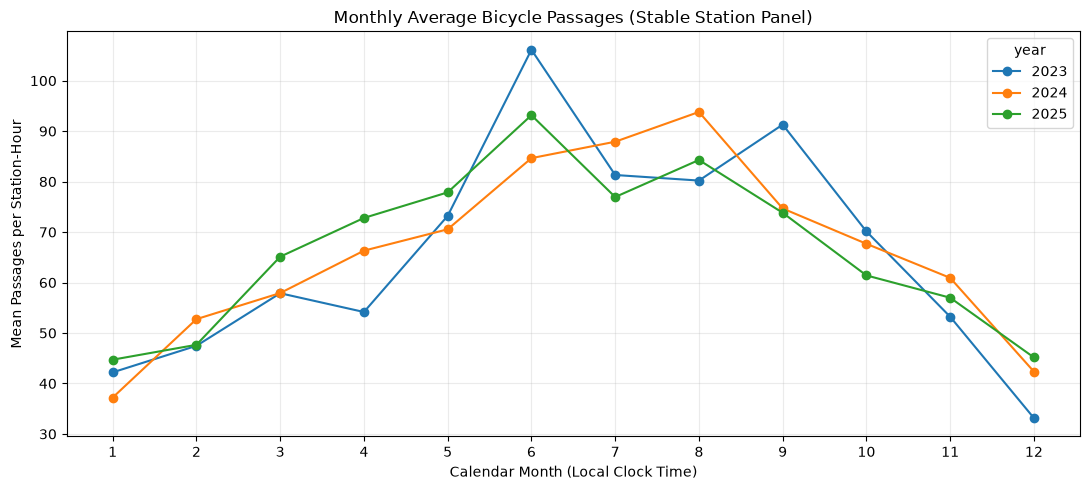

In [19]:
# Calculate comparable monthly averages for the stable station panel
panel_monthly = (
    velo_panel.groupby(["year", "month"])["velo_total"]
    .agg(mean_passages="mean", station_hours="size")
    .reset_index()
)
monthly_profiles = panel_monthly.pivot(
    index="month", columns="year", values="mean_passages"
)
print("Monthly mean passages per observed station-hour:")
display(monthly_profiles.round(2))

ax = monthly_profiles.plot(marker="o", figsize=(11, 5))
ax.set(
    title="Monthly Average Bicycle Passages (Stable Station Panel)",
    xlabel="Calendar Month (Local Clock Time)",
    ylabel="Mean Passages per Station-Hour",
)
ax.set_xticks(range(1, 13))
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(figure_dir / "velo_monthly_mean_by_year.png", dpi=150)
plt.show()

### 2.8 Variation between counting stations

Different stations can have very different activity levels. The following ranking uses the **mean total passages per observed standard station-hour** for each station, rather than raw cumulative totals that would favor stations with more recorded hours.

The figure contains station IDs only. Geographic station names and coordinates are not included in this CSV and must be obtained from a separately documented lookup table before creating a geographic visualization.

Top counting stations by mean passages per observed station-hour:


,mean_passages,observed_station_hours
FK_STANDORT,,
2989,149.76,26274
4249,129.49,26272
4272,127.53,5758
1037,109.72,26274
3008,102.31,3717
4273,100.19,5375
4267,92.84,21305
4266,88.23,22691
4259,84.73,24922


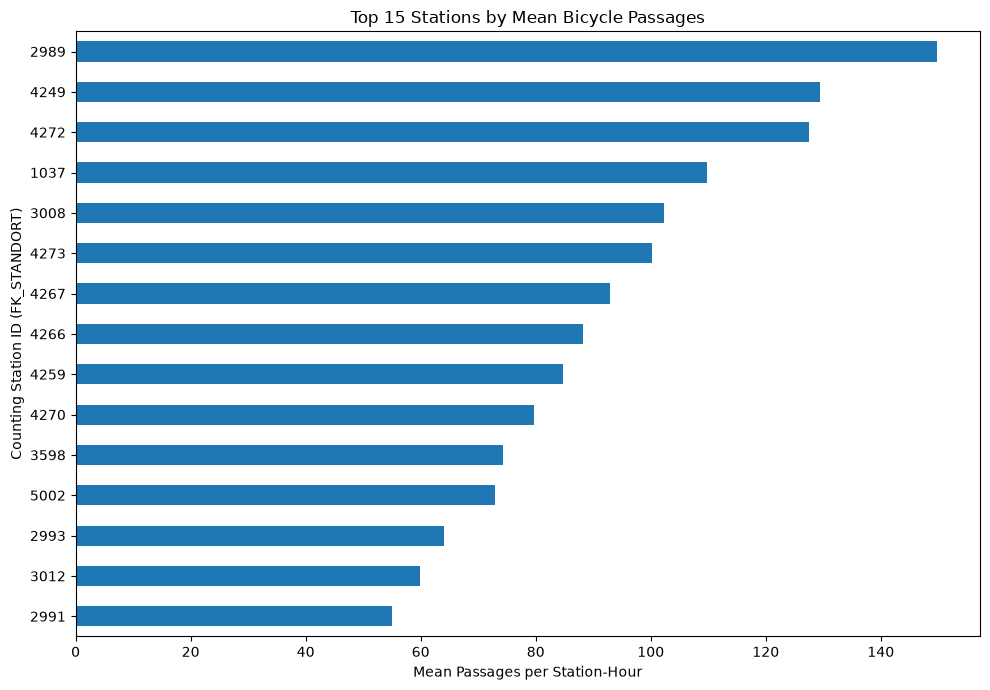

In [20]:
# Rank stations by average passages per observed standard station-hour
station_means = (
    velo_standard.groupby("FK_STANDORT")["velo_total"]
    .agg(mean_passages="mean", observed_station_hours="size")
    .sort_values("mean_passages", ascending=False)
)
print("Top counting stations by mean passages per observed station-hour:")
display(station_means.head(15).round(2))

ax = (
    station_means.head(15)["mean_passages"].sort_values()
    .plot(kind="barh", figsize=(10, 7))
)
ax.set(
    title="Top 15 Stations by Mean Bicycle Passages",
    xlabel="Mean Passages per Station-Hour",
    ylabel="Counting Station ID (FK_STANDORT)",
)
plt.tight_layout()
plt.savefig(figure_dir / "velo_top_stations_mean.png", dpi=150)
plt.show()


### 2.9 Bicycle EDA Interpretation

#### Data Quality
The bicycle traffic dataset contains 587,954 hourly
records from 33 counting stations in Zurich,
covering the period from 2023 to 2025.

A total of 68,774 records have missing values
in the `velo_out` column. This does not necessarily
indicate a data quality problem, as some stations
only measure bicycle traffic in one direction.

No duplicate station-hour combinations were found.
The existing `velo_total` column is used for
the traffic analysis.

#### Daylight-Saving Time
The bicycle data contains local timestamps affected
by daylight-saving time transitions.

Three spring-forward hours are absent from the
dataset, corresponding to the clock changes
in March 2023, 2024 and 2025.

Additionally, 66 records contain eight measurement
intervals instead of the usual four, associated
with the autumn clock changes.

These differences must be considered when
integrating the bicycle data with UTC weather data.

#### Station Coverage
The number of available counting stations varies
throughout the observation period.

This makes comparisons of total bicycle passages
across different years potentially misleading.

To improve comparability, a stable panel of
12 counting stations was selected for the
temporal analyses.

#### Daily Traffic Patterns
Bicycle traffic shows clear differences throughout
the day.

Two major peaks can be observed, particularly
around 08:00 and between 17:00 and 18:00.

These patterns are consistent with typical
commuting hours, although trip purposes cannot
be directly identified from the dataset.

#### Weekday and Weekend Differences
Average bicycle traffic is generally higher
on weekdays than on weekends.

The highest average weekday traffic occurs
on Tuesday, with approximately 79 passages
per recorded station-hour.

Sunday shows the lowest average, with
approximately 41 passages per station-hour.

Weekend traffic also shows a different daily
profile, with less pronounced commuting peaks.

#### Seasonal Traffic Patterns
Bicycle traffic varies considerably across
the months of the year.

In the stable station panel, June has the
highest average traffic, with approximately
95 passages per station-hour.

December has the lowest average, with
approximately 40 passages per station-hour.

This indicates a clear seasonal pattern in
the recorded bicycle traffic.

#### Limitations
The analysis describes recorded bicycle passages
at selected counting stations rather than the
total number of unique cyclists in Zurich.

Differences between seasons may be related to
weather, daylight, holidays, commuting patterns
or other factors.

Because bicycle and weather data have not yet
been integrated, no direct relationship between
weather conditions and bicycle traffic can be
established at this stage.


## 3. Next step: EDA of the integrated dataset (pending member A)

The separate EDA is complete once both datasets and the figures above have been inspected. The following tasks require the integrated weather–bicycle file:

1. Document the integration keys, number of matched and unmatched records, and whether the analysis unit is **one station-hour** or **one citywide hour**.
2. Verify that the UTC weather timestamp and the local bicycle `stunde` are reconciled correctly. In particular, the local spring-forward `02:00` is absent, whereas the autumn `02:00` may combine two distinct hours into a row with eight underlying intervals. Avoid an implicit, one-to-one join that duplicates or misaligns these observations.
3. Compare bicycle traffic in **wet versus dry hours** and across temperature ranges. Consider station, hour-of-day, weekday, and season as confounders.
4. Recheck the total number of observations and station coverage after integration.
5. Summarize substantive results without presenting association as causation.

**Modeling (future notebooks):** Statistical inference with appropriate p-values, regression, model evaluation, and optional clustering belong in the subsequent analysis notebooks. They should not be presented as completed here.

## AI usage note

Document in the project's AI reflection which tools helped with code construction and interpretation, what you checked independently, and any incorrect assumptions or failed attempts. For example, the timezone handling and missing outbound direction require validation against the original bicycle preparation pipeline.